In [7]:
import pandas as pd
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# Base folder provided
BASE_DIR = Path(r"D:\GradSchool\DAAN862\Lesson8")

# File paths
REG_PATH     = BASE_DIR / "breastcancer.csv"

# Load
df     = pd.read_csv(REG_PATH)
df.head()

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114,1
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786,1
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697,1
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220,1
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920,1



BASIC SHAPE & DTYPES
Rows: 116  |  Columns: 10

Dtypes:
Age                 int64
BMI               float64
Glucose             int64
Insulin           float64
HOMA              float64
Leptin            float64
Adiponectin       float64
Resistin          float64
MCP-1             float64
Classification      int64
dtype: object

MISSING VALUES
No missing values detected.

DUPLICATE ROWS
Duplicate rows (full-row duplicates): 0

DISTRIBUTION (Classification: 1=Healthy, 2=Patients)
                count  percent
Classification                
1                  52    44.83
2                  64    55.17

NUMERIC SUMMARY
             count        mean         std        min         25%         50%         75%          max
Age          116.0   57.301724   16.112766  24.000000   45.000000   56.000000   71.000000    89.000000
BMI          116.0   27.582111    5.020136  18.370000   22.973205   27.662416   31.241442    38.578759
Glucose      116.0   97.793103   22.525162  60.000000   85.750000

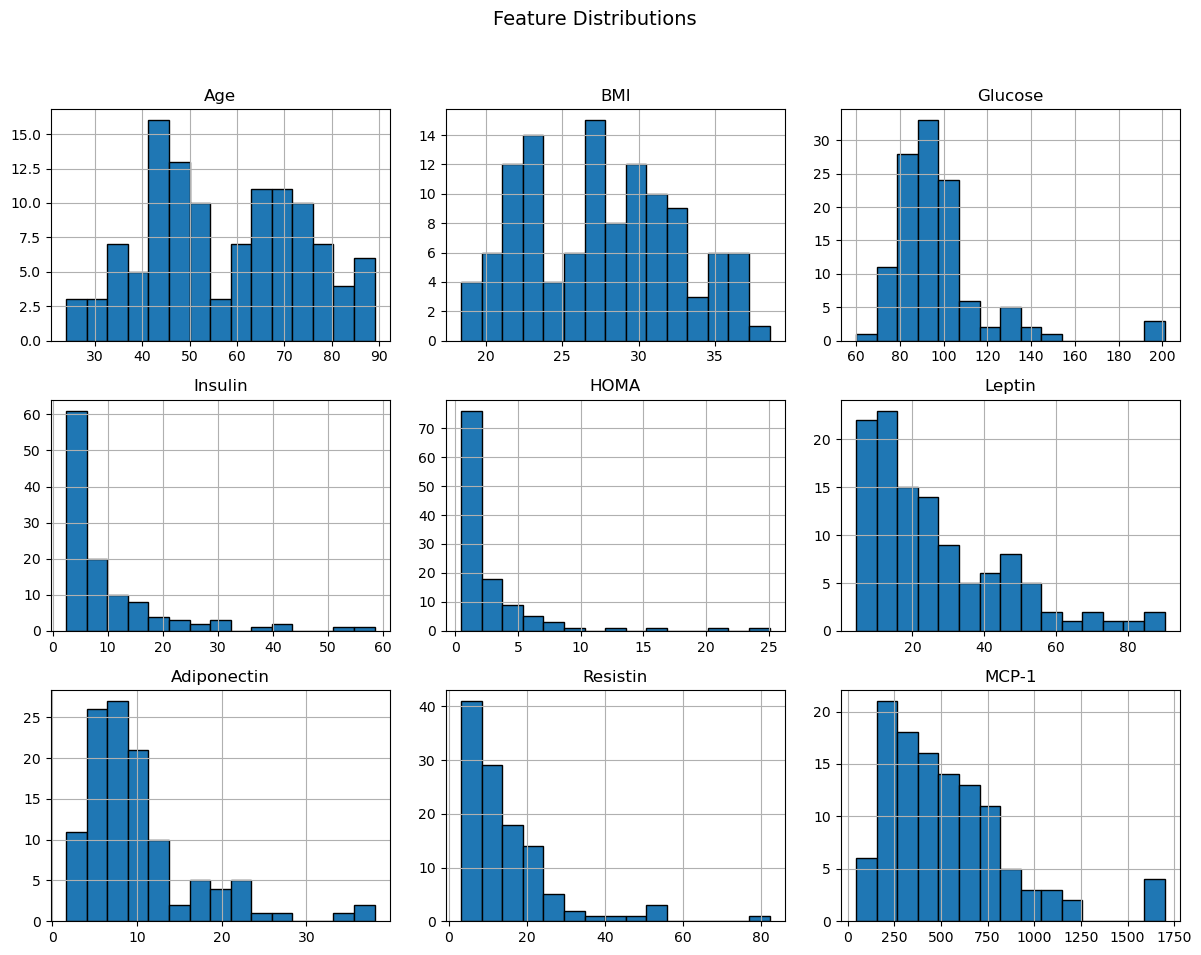


DISTRIBUTIONS – BOXPLOTS


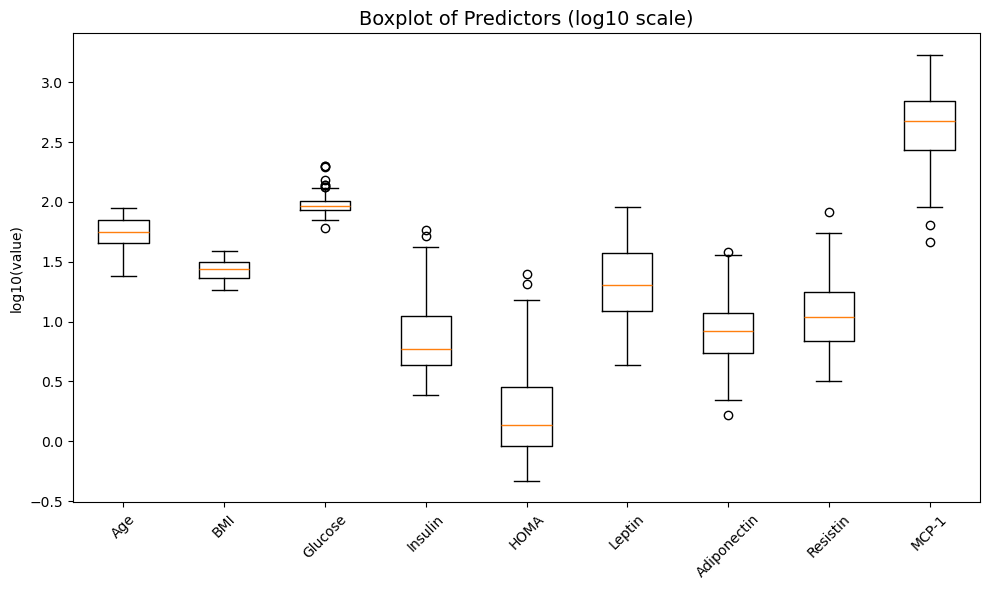

In [8]:
# ---------------------------------------------------------------------------
# Question 1.1 – Perform Exploratory Data Analysis
# ---------------------------------------------------------------------------

# optional display settings
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# --- basic cleanup (if needed)
df = df.copy()
if "MCP-1" not in df.columns and "MCP.1" in df.columns:
    df = df.rename(columns={"MCP.1": "MCP-1"})

label_col = "Classification"
num_cols = [c for c in df.columns if c != label_col]

# ================= SHAPE / DTYPES =================
print("\n" + "="*70)
print("BASIC SHAPE & DTYPES")
print("="*70)
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
print("\nDtypes:")
print(df.dtypes)

# ================= MISSING VALUES =================
print("\n" + "="*70)
print("MISSING VALUES")
print("="*70)
na_ct = df.isna().sum()
if na_ct.sum() == 0:
    print("No missing values detected.")
else:
    na_tbl = pd.DataFrame({
        "missing_count": na_ct,
        "missing_pct": (na_ct / len(df) * 100).round(2)
    }).sort_values("missing_count", ascending=False)
    print(na_tbl[na_tbl["missing_count"] > 0])

# ================= DUPLICATES =================
print("\n" + "="*70)
print("DUPLICATE ROWS")
print("="*70)
dup_count = df.duplicated().sum()
print(f"Duplicate rows (full-row duplicates): {dup_count:,}")

# ================= DISTRIBUTION =================
print("\n" + "="*70)
print("DISTRIBUTION (Classification: 1=Healthy, 2=Patients)")
print("="*70)
vc = df[label_col].value_counts().sort_index()
pct = (vc / vc.sum() * 100).round(2)
print(pd.DataFrame({"count": vc, "percent": pct}))

# ================= BASIC SUMMARY =================
print("\n" + "="*70)
print("NUMERIC SUMMARY")
print("="*70)
print(df[num_cols].describe().T)

# ================= HISTOGRAMS =================
print("\n" + "="*70)
print("DISTRIBUTIONS – HISTOGRAMS")
print("="*70)
df[num_cols].hist(figsize=(12, 10), bins=15, edgecolor='black')
plt.suptitle("Feature Distributions", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ================= BOX PLOTS =================
print("\n" + "="*70)
print("DISTRIBUTIONS – BOXPLOTS")
print("="*70)

label_col = "Classification"
num_cols = [c for c in df.columns if c != label_col]
X = df[num_cols].copy()

nonpos = (X <= 0).sum()
if (nonpos > 0).any():
    print("\nNon-positive values replaced with NaN before log10 transform:")
    print(nonpos[nonpos > 0])

X_log = np.log10(X.where(X > 0))

# Decide which kwarg to use based on version
maj, min_ = (int(x) for x in matplotlib.__version__.split(".")[:2])
label_kw = {"tick_labels" if (maj, min_) >= (3, 9) else "labels": num_cols}

plt.figure(figsize=(10, 6))
plt.boxplot([X_log[col].dropna() for col in num_cols], vert=True, showfliers=True, **label_kw)
plt.title("Boxplot of Predictors (log10 scale)", fontsize=14)
plt.ylabel("log10(value)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


DATA SPLIT
Training set: 81 rows
Test set:     35 rows

LOGISTIC REGRESSION RESULTS
Accuracy: 0.800

Confusion Matrix:
[[14  2]
 [ 5 14]]

Classification Report:
              precision    recall  f1-score   support

           1      0.737     0.875     0.800        16
           2      0.875     0.737     0.800        19

    accuracy                          0.800        35
   macro avg      0.806     0.806     0.800        35
weighted avg      0.812     0.800     0.800        35


FEATURE IMPORTANCE (by absolute coefficient)
       Feature  Coefficient  AbsCoeff
2      Glucose     1.910354  1.910354
7     Resistin     0.529550  0.529550
1          BMI    -0.459498  0.459498
0          Age    -0.411157  0.411157
5       Leptin    -0.408686  0.408686
4         HOMA     0.275501  0.275501
6  Adiponectin    -0.262470  0.262470
3      Insulin     0.246737  0.246737
8        MCP-1     0.082653  0.082653


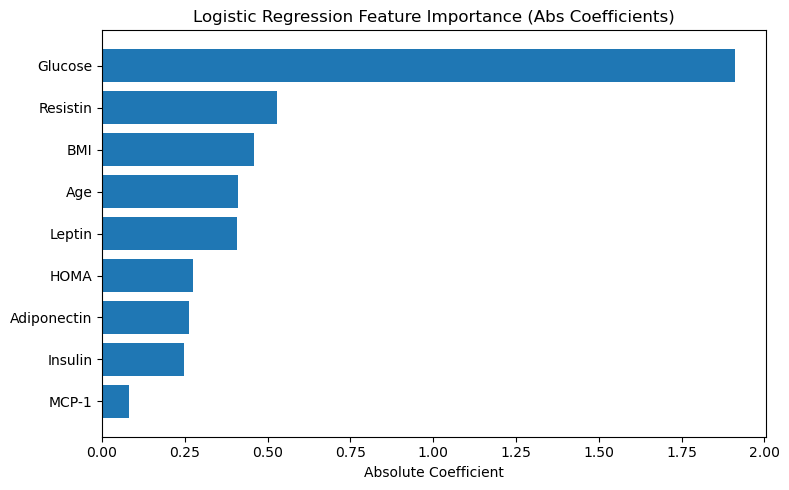

In [9]:
# ---------------------------------------------------------------------------
# Question 1.2 – Logistic Regression Model (70/30 Train–Test Split)
# ---------------------------------------------------------------------------

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- feature / target split
X = df.drop(columns=["Classification"])
y = df["Classification"]

# --- 70/30 split (30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("\n" + "="*70)
print("DATA SPLIT")
print("="*70)
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set:     {X_test.shape[0]:,} rows")

# --- scale numeric predictors
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# --- fit logistic regression
log_reg = LogisticRegression(max_iter=1000, solver='lbfgs')
log_reg.fit(X_train_scaled, y_train)

# --- predictions
y_pred = log_reg.predict(X_test_scaled)

# --- evaluation
print("\n" + "="*70)
print("LOGISTIC REGRESSION RESULTS")
print("="*70)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

# --- feature importance (absolute coefficients)
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_reg.coef_[0],
    "AbsCoeff": np.abs(log_reg.coef_[0])
}).sort_values("AbsCoeff", ascending=False)

print("\n" + "="*70)
print("FEATURE IMPORTANCE (by absolute coefficient)")
print("="*70)
print(coef_df)

# Optional: quick visualization of coefficient magnitudes
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.barh(coef_df["Feature"], coef_df["AbsCoeff"])
plt.title("Logistic Regression Feature Importance (Abs Coefficients)")
plt.xlabel("Absolute Coefficient")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [10]:
# ---------------------------------------------------------------------------
# Question 1.3 – Naïve Bayes Model (GaussianNB)
# ---------------------------------------------------------------------------

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- use same train/test split from Question 1.2 ---
# (X_train_scaled, X_test_scaled, y_train, y_test already defined)

# --- fit Naïve Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# --- predictions
y_pred_nb = nb_model.predict(X_test_scaled)

# --- evaluation
print("\n" + "="*70)
print("NAÏVE BAYES RESULTS")
print("="*70)
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, digits=3))

# --- Feature likelihood insights (optional)
# Although GaussianNB doesn’t produce standard coefficients,
# we can examine the class means for rough directionality
means_df = pd.DataFrame(nb_model.theta_, columns=X.columns).T
means_df.columns = [f"Class_{cls}" for cls in nb_model.classes_]
means_df["Diff_(2-1)"] = means_df.iloc[:,1] - means_df.iloc[:,0]

print("\n" + "="*70)
print("NAIVE BAYES FEATURE MEANS BY CLASS")
print("="*70)
print(means_df)



NAÏVE BAYES RESULTS
Accuracy: 0.686

Confusion Matrix:
[[15  1]
 [10  9]]

Classification Report:
              precision    recall  f1-score   support

           1      0.600     0.938     0.732        16
           2      0.900     0.474     0.621        19

    accuracy                          0.686        35
   macro avg      0.750     0.706     0.676        35
weighted avg      0.763     0.686     0.671        35


NAIVE BAYES FEATURE MEANS BY CLASS
              Class_1   Class_2  Diff_(2-1)
Age          0.078002 -0.062401   -0.140403
BMI          0.099180 -0.079344   -0.178525
Glucose     -0.475071  0.380057    0.855128
Insulin     -0.255711  0.204569    0.460280
HOMA        -0.296825  0.237460    0.534285
Leptin       0.046114 -0.036891   -0.083005
Adiponectin  0.100114 -0.080091   -0.180205
Resistin    -0.229743  0.183795    0.413538
MCP-1       -0.081676  0.065341    0.147016



DECISION TREE RESULTS
Accuracy: 0.771

Confusion Matrix:
[[13  3]
 [ 5 14]]

Classification Report:
              precision    recall  f1-score   support

           1      0.722     0.812     0.765        16
           2      0.824     0.737     0.778        19

    accuracy                          0.771        35
   macro avg      0.773     0.775     0.771        35
weighted avg      0.777     0.771     0.772        35


FEATURE IMPORTANCE (Gini)
       Feature    Importance
2      Glucose  4.039900e-01
1          BMI  2.473852e-01
7     Resistin  1.101284e-01
4         HOMA  7.282913e-02
8        MCP-1  6.833036e-02
5       Leptin  4.115226e-02
6  Adiponectin  3.703704e-02
0          Age  1.914757e-02
3      Insulin  2.775558e-17


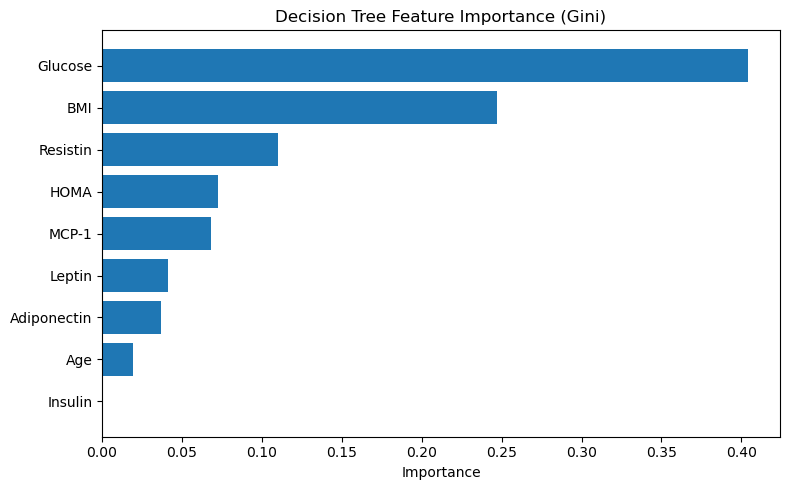

In [11]:
# ---------------------------------------------------------------------------
# Question 1.4 – Decision Tree Model (sklearn.tree)
# ---------------------------------------------------------------------------

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reuse X_train, X_test, y_train, y_test from Q1.2 (UNSCALED features for trees)
# If they aren't in scope, do:
# X = df.drop(columns=["Classification"]); y = df["Classification"]
# from sklearn.model_selection import train_test_split
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.30, random_state=42, stratify=y
# )

# Fit a basic decision tree (class_weight helps if classes are imbalanced)
dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"  # remove if you prefer pure counts
)
dt.fit(X_train, y_train)

# Predictions
y_pred_dt = dt.predict(X_test)

# Evaluation
print("\n" + "="*70)
print("DECISION TREE RESULTS")
print("="*70)
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, digits=3))

# Feature importance (Gini importance)
imp_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": dt.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n" + "="*70)
print("FEATURE IMPORTANCE (Gini)")
print("="*70)
print(imp_df)

# Optional: visualize importances
plt.figure(figsize=(8, 5))
plt.barh(imp_df["Feature"], imp_df["Importance"])
plt.title("Decision Tree Feature Importance (Gini)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [12]:
# ---------------------------------------------------------------------------
# Question 1.5 – Neural Network Model (MLPClassifier)
# ---------------------------------------------------------------------------

import pandas as pd
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Reuse the scaled train/test from Q1.2 (X_train_scaled, X_test_scaled, y_train, y_test)
# If not in scope, recreate the split + scaling exactly as in Q1.2.

# Fit a simple feedforward neural net
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),   # modest architecture
    activation="relu",
    solver="adam",
    alpha=1e-4,                    # L2 regularization
    max_iter=1000,
    random_state=42,
    early_stopping=True,           # hold-out validation for stopping
    n_iter_no_change=20,
    verbose=False
)
mlp.fit(X_train_scaled, y_train)

# Predictions
y_pred_mlp = mlp.predict(X_test_scaled)

# Evaluation
print("\n" + "="*70)
print("NEURAL NETWORK (MLP) RESULTS")
print("="*70)
print(f"Accuracy: {accuracy_score(y_test, y_pred_mlp):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_mlp))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_mlp, digits=3))

# Optional: probabilities if you want threshold analysis later
# y_proba_mlp = mlp.predict_proba(X_test_scaled)



NEURAL NETWORK (MLP) RESULTS
Accuracy: 0.771

Confusion Matrix:
[[14  2]
 [ 6 13]]

Classification Report:
              precision    recall  f1-score   support

           1      0.700     0.875     0.778        16
           2      0.867     0.684     0.765        19

    accuracy                          0.771        35
   macro avg      0.783     0.780     0.771        35
weighted avg      0.790     0.771     0.771        35

